# Práctica 3: word2vec con Skip-gram

En esta práctica entrenamos **embeddings de palabras** con el modelo **Skip-gram** de word2vec.

La idea es la **hipótesis distribucional**: *una palabra se conoce por las palabras que la rodean*.
Si "perro" y "perra" aparecen en contextos parecidos ("el ___ corre en el parque", "la ___ come carne"),
el modelo les asignará vectores parecidos.

**Skip-gram:** dada una palabra central, la red intenta predecir las palabras de su contexto
(las que están a una distancia ≤ `ventana`).

Pasos del notebook:
1. Leer y tokenizar el corpus.
2. Construir el vocabulario.
3. Generar los pares (centro, contexto) con una ventana deslizante.
4. Definir y entrenar la red Skip-gram con PyTorch.
5. Buscar vecinos más cercanos (similitud coseno).
6. Probar analogías (`parís : francia :: madrid : ?`).
7. Visualizar los embeddings en 2D.
8. Estudiar la influencia de los hiperparámetros.

## 0. Librerías y semilla

In [1]:
import random
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

# Fijamos la semilla para que los resultados salgan siempre iguales
def fijar_semilla(semilla=42):
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)

fijar_semilla(42)

## 1. Lectura y tokenización del corpus

El fichero tiene una frase por línea. La tokenización es muy sencilla porque el corpus no tiene
signos de puntuación: pasamos a minúsculas y separamos por espacios.
Cada frase queda como una lista de palabras (tokens).

In [2]:
frases = []
with open("dataset_word2vec.txt", encoding="utf-8") as f:
    for linea in f:
        linea = linea.strip().lower()   # quitamos el salto de línea y pasamos a minúsculas
        if linea != "":                 # ignoramos líneas vacías
            frases.append(linea.split())

print("Número de frases:", len(frases))
print("Ejemplo:", frases[0])
print("Ejemplo:", frases[140])

Número de frases: 251
Ejemplo: ['el', 'perro', 'corre', 'en', 'el', 'parque']
Ejemplo: ['roma', 'está', 'en', 'italia']


## 2. Vocabulario

Necesitamos asignar a cada palabra un número (índice), porque la red trabaja con números.
- `palabra_a_indice`: de palabra a número.
- `indice_a_palabra`: de número a palabra (para interpretar los resultados).

In [3]:
# Contamos cuántas veces aparece cada palabra
conteo = Counter()
for frase in frases:
    conteo.update(frase)

vocabulario = sorted(conteo.keys())   # lista de palabras distintas (ordenada alfabéticamente)

palabra_a_indice = {}
for i, palabra in enumerate(vocabulario):
    palabra_a_indice[palabra] = i

indice_a_palabra = vocabulario   # la posición en la lista es el índice

print("Total de tokens:", sum(conteo.values()))
print("Tamaño del vocabulario:", len(vocabulario))
print("Palabras más frecuentes:", conteo.most_common(10))

Total de tokens: 1148
Tamaño del vocabulario: 356
Palabras más frecuentes: [('la', 131), ('el', 129), ('es', 37), ('está', 27), ('en', 26), ('un', 20), ('por', 15), ('una', 15), ('al', 14), ('gato', 11)]


## 3. Pares (centro, contexto) con ventana deslizante

Recorremos cada frase y, para cada palabra central, cogemos como contexto las palabras que están
como mucho a `ventana` posiciones a su izquierda o derecha.

Ejemplo con `ventana = 2` y la frase *"el perro corre en el parque"*, palabra central **corre**:

`el  perro [corre]  en  el` → pares: (corre, el), (corre, perro), (corre, en), (corre, el)

In [4]:
def generar_pares(frases, ventana):
    pares = []
    for frase in frases:
        for i in range(len(frase)):
            centro = frase[i]
            # posiciones del contexto: de i-ventana a i+ventana sin salirnos de la frase
            inicio = max(0, i - ventana)
            fin = min(len(frase), i + ventana + 1)
            for j in range(inicio, fin):
                if j != i:   # la palabra central no es contexto de sí misma
                    pares.append((centro, frase[j]))
    return pares

# Ejemplo con la primera frase
for par in generar_pares([frases[0]], ventana=2):
    print(par)

('el', 'perro')
('el', 'corre')
('perro', 'el')
('perro', 'corre')
('perro', 'en')
('corre', 'el')
('corre', 'perro')
('corre', 'en')
('corre', 'el')
('en', 'perro')
('en', 'corre')
('en', 'el')
('en', 'parque')
('el', 'corre')
('el', 'en')
('el', 'parque')
('parque', 'en')
('parque', 'el')


In [5]:
VENTANA = 2
pares = generar_pares(frases, VENTANA)
print("Número de pares (centro, contexto):", len(pares))

Número de pares (centro, contexto): 3086


## 4. Modelo Skip-gram

La red es muy sencilla, tiene solo dos capas:

1. **Capa de embedding** (`nn.Embedding`): una tabla de tamaño `V x d` (V = tamaño del vocabulario,
   d = dimensión del embedding). Dado el índice de la palabra central devuelve su vector de `d` números.
   **Estos vectores son los word embeddings que queremos aprender.**
2. **Capa lineal de salida** (`nn.Linear`): pasa del vector de `d` números a `V` puntuaciones,
   una por cada palabra del vocabulario.

Con *softmax* esas puntuaciones se convierten en probabilidades: P(contexto | centro).
La función de pérdida es la **entropía cruzada** (`CrossEntropyLoss`, que ya incluye el softmax):
el modelo aprende a dar probabilidad alta a las palabras que realmente aparecen en el contexto.

> Como el vocabulario es pequeño (~350 palabras) usamos el softmax completo. En corpus grandes se usa
> *negative sampling* para que sea más rápido, pero la idea es la misma.

In [6]:
class SkipGram(nn.Module):
    def __init__(self, tam_vocab, dim_embedding):
        super().__init__()
        self.embeddings = nn.Embedding(tam_vocab, dim_embedding)   # palabra central -> vector
        self.salida = nn.Linear(dim_embedding, tam_vocab)          # vector -> puntuación de cada palabra

    def forward(self, centro):
        vector = self.embeddings(centro)
        puntuaciones = self.salida(vector)
        return puntuaciones

### Función de entrenamiento

La escribimos como función para poder reutilizarla después al probar distintos hiperparámetros.
En cada época barajamos los pares y los recorremos en lotes (*batches*).

In [7]:
def entrenar(ventana, dim_embedding, epocas, lr=0.01, tam_lote=64, semilla=42, mostrar=True):
    fijar_semilla(semilla)

    # 1) Pares (centro, contexto) convertidos a índices
    pares = generar_pares(frases, ventana)
    centros = torch.tensor([palabra_a_indice[c] for c, _ in pares])
    contextos = torch.tensor([palabra_a_indice[x] for _, x in pares])

    # 2) Modelo, función de pérdida y optimizador
    modelo = SkipGram(len(vocabulario), dim_embedding)
    funcion_perdida = nn.CrossEntropyLoss()
    optimizador = torch.optim.Adam(modelo.parameters(), lr=lr)

    # 3) Bucle de entrenamiento
    historial = []
    for epoca in range(epocas):
        orden = torch.randperm(len(pares))      # barajamos los pares en cada época
        perdida_total = 0

        for k in range(0, len(pares), tam_lote):
            lote = orden[k:k + tam_lote]
            x = centros[lote]       # palabras centrales del lote
            y = contextos[lote]     # palabras de contexto que hay que predecir

            optimizador.zero_grad()            # ponemos los gradientes a cero
            prediccion = modelo(x)             # forward
            perdida = funcion_perdida(prediccion, y)
            perdida.backward()                 # calculamos gradientes
            optimizador.step()                 # actualizamos los pesos

            perdida_total += perdida.item() * len(lote)

        perdida_media = perdida_total / len(pares)
        historial.append(perdida_media)
        if mostrar and (epoca + 1) % 10 == 0:
            print(f"Época {epoca + 1:3d} | pérdida = {perdida_media:.4f}")

    return modelo, historial

### Entrenamiento del modelo principal

Hiperparámetros elegidos (justificados en el apartado 8):
- `ventana = 2`
- `dim_embedding = 10` (el corpus es muy pequeño, así que bastan pocos números por palabra)
- `epocas = 100`, `lr = 0.01`, `tam_lote = 64`

In [8]:
DIM = 10
EPOCAS = 100

modelo, historial = entrenar(VENTANA, DIM, EPOCAS)

Época  10 | pérdida = 3.7942


Época  20 | pérdida = 3.2791


Época  30 | pérdida = 3.0686


Época  40 | pérdida = 2.9705


Época  50 | pérdida = 2.9120


Época  60 | pérdida = 2.8730


Época  70 | pérdida = 2.8480


Época  80 | pérdida = 2.8255


Época  90 | pérdida = 2.8101


Época 100 | pérdida = 2.8003


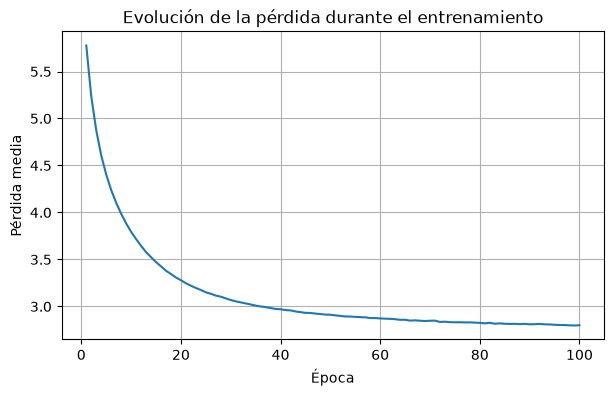

In [9]:
plt.figure(figsize=(7, 4))
plt.plot(range(1, EPOCAS + 1), historial)
plt.xlabel("Época")
plt.ylabel("Pérdida media")
plt.title("Evolución de la pérdida durante el entrenamiento")
plt.grid(True)
plt.show()

La pérdida baja rápido al principio y luego se estabiliza. No llega a cero, y es normal: una misma
palabra central tiene muchos contextos posibles (por ejemplo, después de "el" puede ir casi cualquier
sustantivo), así que el modelo nunca puede acertar con probabilidad 1.

## 5. Vecinos más cercanos (similitud coseno)

Sacamos la matriz de embeddings (los pesos de la capa `nn.Embedding`) y la normalizamos: dividimos cada
vector por su longitud. Así, el **producto escalar** entre dos vectores es directamente su **similitud coseno**:

$$\cos(u, v) = \frac{u \cdot v}{\|u\|\,\|v\|}$$

Vale 1 si los vectores apuntan en la misma dirección y valores cercanos a 0 (o negativos) si no se parecen.

In [10]:
def obtener_embeddings(modelo):
    E = modelo.embeddings.weight.detach().numpy()      # matriz V x d
    normas = np.linalg.norm(E, axis=1, keepdims=True)  # longitud de cada vector
    return E / normas                                   # vectores de longitud 1

def vecinos_mas_cercanos(E, palabra, k=5):
    vector = E[palabra_a_indice[palabra]]
    similitudes = E @ vector                 # similitud coseno con todas las palabras
    orden = np.argsort(-similitudes)         # índices ordenados de mayor a menor similitud
    resultado = []
    for i in orden:
        if indice_a_palabra[i] != palabra:   # no devolvemos la propia palabra
            resultado.append((indice_a_palabra[i], similitudes[i]))
        if len(resultado) == k:
            break
    return resultado

E = obtener_embeddings(modelo)
print("Forma de la matriz de embeddings:", E.shape)
print("Vector de 'perro':", np.round(E[palabra_a_indice["perro"]], 2))
print()
for palabra, sim in vecinos_mas_cercanos(E, "perro"):
    print(f"{palabra:10s} {sim:.3f}")

Forma de la matriz de embeddings: (356, 10)
Vector de 'perro': [-0.5  -0.45  0.28  0.57 -0.11  0.22  0.15  0.08 -0.23 -0.  ]

gato       0.981
programador 0.722
ladra      0.684
diseña     0.662
pelota     0.658


### Tabla de vecinos de varias palabras (entregable 2)

In [11]:
palabras_consulta = ["perro", "perra", "gato", "gata", "coche", "parís", "francia",
                     "madrid", "rey", "niño", "café", "mañana"]

filas = {}
for palabra in palabras_consulta:
    vecinos = vecinos_mas_cercanos(E, palabra, k=5)
    filas[palabra] = [f"{v} ({s:.2f})" for v, s in vecinos]

tabla_vecinos = pd.DataFrame.from_dict(filas, orient="index",
                                       columns=["1º", "2º", "3º", "4º", "5º"])
tabla_vecinos.to_csv("tabla_vecinos.csv")
tabla_vecinos

,1º,2º,3º,4º,5º
perro,gato (0.98),programador (0.72),ladra (0.68),diseña (0.66),pelota (0.66)
perra,gata (0.96),hizo (0.88),entro (0.82),alumna (0.78),programadora (0.77)
gato,perro (0.98),programador (0.71),ratón (0.69),niño (0.68),hermano (0.67)
gata,perra (0.96),entro (0.83),alumna (0.78),hizo (0.77),hermana (0.71)
coche,periódico (0.74),rápido (0.72),lento (0.71),curioso (0.69),niño (0.68)
parís,roma (1.00),madrid (1.00),italia (0.80),francia (0.80),españa (0.80)
francia,españa (1.00),italia (1.00),blanco (0.84),negro (0.82),madrid (0.80)
madrid,roma (1.00),parís (1.00),italia (0.80),francia (0.80),españa (0.80)
rey,reina (0.89),suelo (0.82),sofá (0.82),campo (0.80),corona (0.80)
niño,periódico (0.87),padre (0.87),alumno (0.83),niña (0.83),verano (0.78)


**Comentario de los vecinos:**

- **perro ↔ gato** (0.98) y **perra ↔ gata** (0.96) son casi idénticos: en el corpus aparecen exactamente en las
  mismas frases ("el ___ corre / come / bebe / duerme / juega..."). Es la hipótesis distribucional en acción.
- **parís, madrid y roma** tienen similitud ≈ 1.00 entre ellas, igual que **francia, españa e italia**: sus frases
  son literalmente iguales salvo por esa palabra ("___ es una ciudad", "___ está en ...").
- **rey → reina** (0.89) y **café → té / bebe** también tienen sentido.
- Aparecen vecinos "raros" (perro → programador, coche → periódico, mañana → estudias). Esto se debe a que el
  corpus es **muy pequeño** (1148 tokens) y muchas palabras aparecen 1 o 2 veces: comparten algún contexto
  como "el ___ escribe" y el modelo no tiene más información para distinguirlas.
- El modelo agrupa por **contexto gramatical**, no solo por significado: las palabras que van con "el"
  (perro, gato, programador) quedan juntas, y las que van con "la" (perra, gata, alumna, programadora) también.

## 6. Analogías (entregable 3)

Una analogía `a : b :: c : ?` se lee "*a es a b lo que c es a ?*". Se resuelve con aritmética de vectores:

$$? \approx \vec{b} - \vec{a} + \vec{c}$$

Por ejemplo, `francia - parís` representa la relación "capital → país"; si se la sumamos a `madrid`
deberíamos acercarnos a `españa`. Buscamos la palabra más parecida (coseno) a ese vector, excluyendo
`a`, `b` y `c`.

In [12]:
def analogia(E, a, b, c, k=3):
    vector = E[palabra_a_indice[b]] - E[palabra_a_indice[a]] + E[palabra_a_indice[c]]
    vector = vector / np.linalg.norm(vector)
    similitudes = E @ vector
    orden = np.argsort(-similitudes)
    resultado = []
    for i in orden:
        if indice_a_palabra[i] not in (a, b, c):
            resultado.append(indice_a_palabra[i])
        if len(resultado) == k:
            break
    return resultado

print("parís : francia :: madrid : ?  ->", analogia(E, "parís", "francia", "madrid"))

parís : francia :: madrid : ?  -> ['españa', 'italia', 'blanco']


In [13]:
# (a, b, c, respuesta esperada)
analogias = [
    ("parís", "francia", "madrid", "españa"),
    ("madrid", "españa", "roma", "italia"),
    ("perro", "perra", "gato", "gata"),
    ("niño", "niña", "padre", "madre"),
    ("rey", "reina", "padre", "madre"),
    ("abuelo", "abuela", "hermano", "hermana"),
    ("médico", "médica", "enfermero", "enfermera"),
    ("perro", "perra", "niño", "niña"),
    ("ingeniero", "ingeniera", "programador", "programadora"),
    ("el", "la", "perro", "perra"),
]

def evaluar_analogias(E, analogias):
    filas = []
    aciertos = 0
    for a, b, c, esperada in analogias:
        top3 = analogia(E, a, b, c, k=3)
        acierto = (top3[0] == esperada)
        aciertos += acierto
        filas.append([f"{a} : {b} :: {c} : ?", esperada, ", ".join(top3), "✔" if acierto else "✘"])
    tabla = pd.DataFrame(filas, columns=["Analogía", "Esperada", "Top-3 del modelo", "Acierto (top-1)"])
    return tabla, aciertos

tabla_analogias, aciertos = evaluar_analogias(E, analogias)
tabla_analogias.to_csv("tabla_analogias.csv", index=False)
print(f"Aciertos: {aciertos} de {len(analogias)}")
tabla_analogias

Aciertos: 10 de 10


,Analogía,Esperada,Top-3 del modelo,Acierto (top-1)
0,parís : francia :: madrid : ?,españa,"españa, italia, blanco",✔
1,madrid : españa :: roma : ?,italia,"italia, francia, blanco",✔
2,perro : perra :: gato : ?,gata,"gata, hizo, entro",✔
3,niño : niña :: padre : ?,madre,"madre, cocinera, periódico",✔
4,rey : reina :: padre : ?,madre,"madre, niña, cocinera",✔
5,abuelo : abuela :: hermano : ?,hermana,"hermana, voleibol, maestro",✔
6,médico : médica :: enfermero : ?,enfermera,"enfermera, voy, madre",✔
7,perro : perra :: niño : ?,niña,"niña, profesora, ciudad",✔
8,ingeniero : ingeniera :: programador : ?,programadora,"programadora, perra, alumna",✔
9,el : la :: perro : ?,perra,"perra, gata, cacao",✔


**Comentario de las analogías:** el modelo resuelve las 10 analogías, tanto la de **capital → país**
(`parís : francia :: madrid : españa`) como las de **masculino → femenino** (perro/perra, niño/niña, rey/reina...).

La relación de género se aprende sobre todo gracias a los artículos: las palabras masculinas aparecen junto
a "el" y las femeninas junto a "la", así que el vector `perra - perro` es parecido a `la - el`.
Por eso incluso `el : la :: perro : perra` funciona.

Hay que ser prudentes con este 10/10: el corpus está hecho a propósito con frases paralelas y los
hiperparámetros los hemos elegido mirando estas mismas analogías. En el apartado 8.4 se ve que con otras
semillas el resultado baja a 7–8 de 10.

## 7. Visualización en 2D

Los embeddings tienen 10 dimensiones y no se pueden dibujar directamente. Usamos **PCA**
(análisis de componentes principales) para proyectarlos a 2 dimensiones conservando la mayor
parte de la variación. Lo hacemos con numpy: centramos los datos y usamos la descomposición SVD.

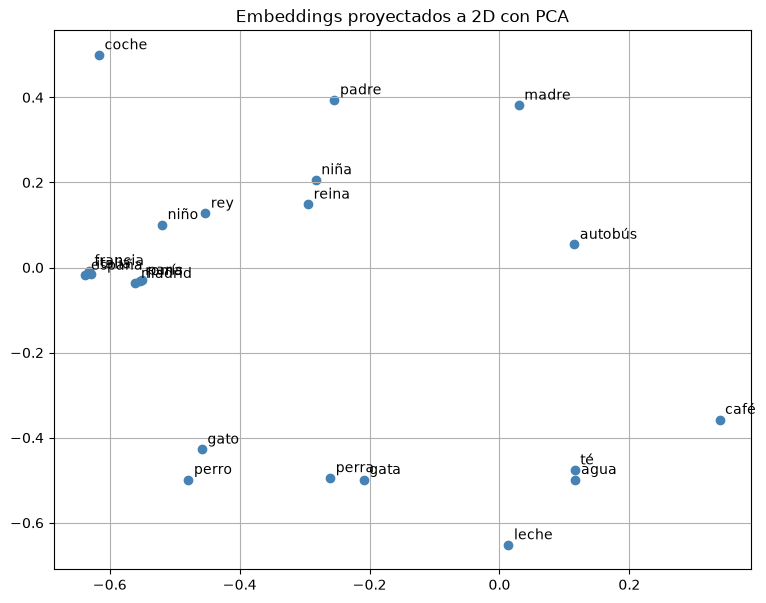

In [14]:
# PCA con numpy
E_centrado = E - E.mean(axis=0)
U, S, Vt = np.linalg.svd(E_centrado)
E_2d = E_centrado @ Vt[:2].T      # proyectamos sobre las 2 primeras componentes

palabras_dibujo = ["perro", "perra", "gato", "gata", "niño", "niña", "padre", "madre",
                   "rey", "reina", "parís", "madrid", "roma", "francia", "españa", "italia",
                   "coche", "autobús", "café", "té", "leche", "agua"]

plt.figure(figsize=(9, 7))
for palabra in palabras_dibujo:
    x, y = E_2d[palabra_a_indice[palabra]]
    plt.scatter(x, y, color="steelblue")
    plt.annotate(palabra, (x, y), xytext=(4, 4), textcoords="offset points")
plt.title("Embeddings proyectados a 2D con PCA")
plt.grid(True)
plt.show()

**Comentario de la gráfica:**

- **Ciudades** (parís, madrid, roma) y **países** (francia, españa, italia) quedan prácticamente encima unos de otros
  (por eso las etiquetas se solapan), formando dos grupos pegados.
- **Animales** (perro, gato, perra, gata) abajo a la izquierda y **bebidas** (té, agua, leche, café) abajo a la derecha.
- Se ve la dirección del **género**: al pasar de masculino a femenino los puntos se desplazan hacia la derecha
  (perro → perra, gato → gata, niño → niña, rey → reina, padre → madre). Es justo lo que hace que funcionen las analogías.

Hay que recordar que al pasar de 10 a 2 dimensiones se pierde información, así que la gráfica es solo orientativa.

## 8. Influencia de los hiperparámetros

Entrenamos el modelo cambiando **un hiperparámetro cada vez** y dejando el resto como en el modelo
principal (ventana = 2, dimensión = 10, épocas = 100). Para comparar usamos:
- **Aciertos en las 10 analogías** (top-1): mide si el espacio vectorial ha capturado las relaciones.
- **Vecinos de "perro"**: comprobación cualitativa.
- La **pérdida final**, con cuidado: con ventanas distintas el problema cambia (hay más pares y más
  difíciles), así que la pérdida solo es comparable entre modelos con la misma ventana.

In [15]:
def experimento(ventana, dim, epocas):
    modelo_exp, hist = entrenar(ventana, dim, epocas, mostrar=False)
    E_exp = obtener_embeddings(modelo_exp)
    _, aciertos = evaluar_analogias(E_exp, analogias)
    vecinos = [v for v, _ in vecinos_mas_cercanos(E_exp, "perro", k=3)]
    return [ventana, dim, epocas, round(hist[-1], 3), f"{aciertos}/{len(analogias)}", ", ".join(vecinos)]

columnas = ["Ventana", "Dimensión", "Épocas", "Pérdida final", "Analogías", "Vecinos de 'perro'"]

### 8.1 Dimensión del embedding

In [16]:
filas = []
for dim in [2, 5, 10, 20, 50, 100]:
    filas.append(experimento(ventana=2, dim=dim, epocas=100))
pd.DataFrame(filas, columns=columnas)

,Ventana,Dimensión,Épocas,Pérdida final,Analogías,Vecinos de 'perro'
0,2,2,100,4.128,0/10,"maúlla, estudiante, pequeño"
1,2,5,100,3.287,3/10,"pequeño, gato, ladra"
2,2,10,100,2.800,10/10,"gato, programador, ladra"
3,2,20,100,2.747,4/10,"gato, perra, voleibol"
4,2,50,100,2.828,3/10,"gato, perra, cuaderno"
5,2,100,100,2.898,4/10,"gato, patio, perra"


**Dimensión:** es el hiperparámetro que más influye en este corpus.
- Con **2 o 5** dimensiones el modelo no tiene capacidad suficiente para separar las palabras (0 y 3 aciertos; la pérdida es mucho más alta).
- **10** es el mejor valor (10/10).
- Con **20, 50 o 100** la pérdida es parecida o algo menor, pero las analogías empeoran (3–4/10). Con tantos números
  por palabra y tan pocos datos, el modelo puede *memorizar* contextos concretos de cada palabra en vez de
  aprender una estructura común, y los vectores son más "ruidosos". En corpus grandes se usan 100–300 dimensiones,
  pero aquí hay solo 356 palabras y 1148 tokens.

### 8.2 Tamaño de la ventana

In [17]:
filas = []
for ventana in [1, 2, 3, 5]:
    filas.append(experimento(ventana=ventana, dim=10, epocas=100))
pd.DataFrame(filas, columns=columnas)

,Ventana,Dimensión,Épocas,Pérdida final,Analogías,Vecinos de 'perro'
0,1,10,100,2.206,6/10,"gato, pájaro, sofá"
1,2,10,100,2.800,10/10,"gato, programador, ladra"
2,3,10,100,3.086,8/10,"gato, parque, negro"
3,5,10,100,3.182,5/10,"grande, gato, parque"


**Ventana:**
- Con **ventana 1** solo se mira la palabra de al lado, que casi siempre es un artículo ("el", "la"), y se pierde parte
  de la información (6/10).
- Con **ventana 2** se capta el artículo y también el verbo o sustantivo cercano: mejor resultado (10/10).
- Con ventanas **grandes (3–5)** las frases son tan cortas (4–6 palabras) que el contexto acaba siendo casi la frase
  entera; se mezclan palabras poco relacionadas y los resultados bajan (8/10 y 5/10). Por ejemplo, con ventana 5
  los vecinos de "perro" son "grande" y "parque", más temáticos que de "misma categoría".
- La pérdida sube con la ventana, pero no significa que el modelo sea peor: con más contexto hay más pares y la tarea
  de predicción es más difícil.

### 8.3 Número de épocas

In [18]:
filas = []
for epocas in [10, 30, 100, 200]:
    filas.append(experimento(ventana=2, dim=10, epocas=epocas))
pd.DataFrame(filas, columns=columnas)

,Ventana,Dimensión,Épocas,Pérdida final,Analogías,Vecinos de 'perro'
0,2,10,10,3.794,0/10,"patio, gato, hizo"
1,2,10,30,3.069,6/10,"gato, hizo, invierno"
2,2,10,100,2.800,10/10,"gato, programador, ladra"
3,2,10,200,2.749,9/10,"gato, programador, ratón"


**Épocas:**
- Con **10 épocas** el modelo no ha terminado de aprender (pérdida alta, 0/10).
- A partir de **100** la pérdida ya casi no baja y los resultados se estabilizan (10/10 con 100, 9/10 con 200).
- Más épocas no mejoran nada y tardan más; en un corpus tan pequeño incluso pueden sobreajustar un poco.

### 8.4 Influencia de la semilla aleatoria

Con un corpus tan pequeño, la inicialización aleatoria de los pesos puede cambiar el resultado. Repetimos el
entrenamiento con 5 semillas distintas para dimensión 10 y dimensión 50 (ventana 2, 100 épocas).

In [19]:
filas = []
for semilla in [0, 1, 2, 3, 42]:
    fila = [semilla]
    for dim in [10, 50]:
        modelo_s, _ = entrenar(2, dim, 100, semilla=semilla, mostrar=False)
        _, aciertos = evaluar_analogias(obtener_embeddings(modelo_s), analogias)
        fila.append(f"{aciertos}/{len(analogias)}")
    filas.append(fila)
pd.DataFrame(filas, columns=["Semilla", "Analogías (dim = 10)", "Analogías (dim = 50)"])

,Semilla,Analogías (dim = 10),Analogías (dim = 50)
0,0,8/10,4/10
1,1,8/10,6/10
2,2,7/10,3/10
3,3,7/10,3/10
4,42,10/10,3/10


**Semilla:** el número de aciertos varía de una semilla a otra (con dimensión 10, entre 7 y 10), así que el 10/10 del
modelo principal es en parte suerte. Lo importante es que **la conclusión se mantiene con todas las semillas**:
dimensión 10 siempre da bastantes más aciertos que dimensión 50 (entre 3 y 6).

## 9. Conclusiones (entregable 4)

1. **Skip-gram funciona incluso con una red de solo dos capas**: los embeddings aprenden que perro/gato,
   parís/madrid/roma o francia/españa/italia son parecidos solo a partir de los contextos en que aparecen.
2. **Las analogías se pueden resolver con sumas y restas de vectores**, porque relaciones como "capital → país"
   o "masculino → femenino" se convierten en direcciones del espacio vectorial (se ve en la gráfica PCA).

**¿Qué hiperparámetros influyen más y por qué?**

- **Dimensión del embedding** (el que más): tiene que estar adaptada a la cantidad de datos. Muy pequeña → no cabe la
  información (2–5 dimensiones fallan). Muy grande → con un corpus diminuto el modelo memoriza y los vectores son
  ruidosos (20–100 empeoran). Con nuestro corpus el mejor valor es 10, y esto se mantiene con todas las semillas probadas.
- **Tamaño de la ventana**: decide *qué* tipo de similitud se aprende. Ventana pequeña → similitud más gramatical
  ("palabras que pueden ir en el mismo hueco"). Ventana grande → similitud más temática ("palabras que salen en la
  misma frase"). Con frases de 4–6 palabras, ventana 2 es el mejor equilibrio.
- **Número de épocas**: tiene que ser suficiente para que la pérdida converja (≈100 aquí); a partir de ahí no aporta.
- **Semilla**: con tan pocos datos, la inicialización aleatoria cambia bastante el resultado (7–10 aciertos), así que
  conviene probar varias antes de sacar conclusiones.

**Limitaciones:** el corpus es muy pequeño y artificial (frases repetidas cambiando una palabra), por eso aparecen
vecinos sin sentido para las palabras poco frecuentes y las palabras muy frecuentes como "el" y "la" pesan mucho.
Con un corpus real y grande se usaría *negative sampling* en lugar del softmax completo y *subsampling* de las
palabras frecuentes.